<a href="https://colab.research.google.com/github/Shy-coder16/Machine-Learning/blob/main/PULS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import gradio as gr
import numpy as np
import pandas as pd
import warnings # Add this import

# Placeholder for X_filtered (assuming it's a DataFrame with feature names)
# In a real scenario, X_filtered would come from your data preprocessing steps.
X_filtered = pd.DataFrame(columns=[
    'age', 'sex', 'cp', 'trestbps', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal'
])

In [22]:
from sklearn.metrics import accuracy_score, classification_report

# --- 1. Load the Real Dataset ---
try:
    df_real = pd.read_csv('/heart.csv')
    print("Real dataset loaded successfully!")
    display(df_real.head())
except FileNotFoundError:
    print("Error: 'heart.csv' not found. Please upload your dataset to the Colab environment.")
    df_real = None # Set to None to prevent further errors if file is missing

Real dataset loaded successfully!


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [23]:
import os

# List all files in the current working directory (/content) to find your uploaded file
print("Files in your current workspace:")
for file in os.listdir('.'):
    print(f"- {file}")

Files in your current workspace:
- .config
- heart.csv
- sample_data


In [24]:
import pandas as pd

# Loading 'heart.csv' from the standard Colab upload directory (/content/)
try:
    df_real = pd.read_csv('/content/heart.csv')
    print("Real dataset loaded successfully!")
    display(df_real.head())
except FileNotFoundError:
    print("Error: 'heart.csv' was not found in '/content/'. Please make sure it finished uploading in the left sidebar.")
    df_real = None

Real dataset loaded successfully!


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Define features (X) and target (y) from the real dataset
# Ensure these features match the expected input for the prediction function
features = [
    'age', 'sex', 'cp', 'trestbps', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal'
]
X = df_real[features]
y = df_real['target']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the StandardScaler
scaler_filtered = StandardScaler()
scaler_filtered.fit(X_train)

# Transform the training and testing data
X_train_scaled = scaler_filtered.transform(X_train)
X_test_scaled = scaler_filtered.transform(X_test)

# Initialize and train the Logistic Regression model
model_filtered = LogisticRegression(random_state=42)
model_filtered.fit(X_train_scaled, y_train)

# Evaluate the model (optional, but good for understanding performance)
y_pred = model_filtered.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy on test set: {accuracy:.4f}")

print("Real scaler and model have been trained and assigned to `scaler_filtered` and `model_filtered` using `df_real`.")

Model Accuracy on test set: 0.8852
Real scaler and model have been trained and assigned to `scaler_filtered` and `model_filtered` using `df_real`.


In [26]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61



In [27]:
# Define the prediction function that Gradio will call
def predict_heart_disease(
    age, sex, cp, trestbps, restecg, thalach, exang, oldpeak, slope, ca, thal
):
    # Create a numpy array from the inputs, matching the order of X_filtered
    input_data = np.array([[age, sex, cp, trestbps, restecg, thalach, exang, oldpeak, slope, ca, thal]])

    # Scale the input data using the pre-trained filtered scaler
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        scaled_input_data = scaler_filtered.transform(input_data)

    # Make a prediction using the trained filtered model
    prediction = model_filtered.predict(scaled_input_data)

    # Return a user-friendly string
    if prediction[0] == 1:
        return "Prediction: High Risk of Heart Disease"
    else:
        return "Prediction: Low Risk of Heart Disease"

# Define the input components for Gradio
# Using the feature names from your filtered DataFrame 'X_filtered'
feature_names_filtered = X_filtered.columns.tolist()

inputs_filtered = [
    gr.Number(label=feature_names_filtered[0], value=52, minimum=20, maximum=90, step=1), # age
    gr.Dropdown([0, 1], label=feature_names_filtered[1], value=1), # sex (0=female, 1=male)
    gr.Dropdown([0, 1, 2, 3], label=feature_names_filtered[2], value=2), # cp (chest pain type)
    gr.Number(label=feature_names_filtered[3], value=125, minimum=90, maximum=200, step=1), # trestbps (resting blood pressure)
    gr.Dropdown([0, 1, 2], label=feature_names_filtered[4], value=1), # restecg (resting electrocardiographic results)
    gr.Number(label=feature_names_filtered[5], value=168, minimum=60, maximum=220, step=1), # thalach (maximum heart rate achieved)
    gr.Dropdown([0, 1], label=feature_names_filtered[6], value=0), # exang (exercise induced angina)
    gr.Number(label=feature_names_filtered[7], value=1.0, minimum=0.0, maximum=6.0, step=0.1), # oldpeak (ST depression induced by exercise relative to rest)
    gr.Dropdown([0, 1, 2], label=feature_names_filtered[8], value=2), # slope (the slope of the peak exercise ST segment)
    gr.Dropdown([0, 1, 2, 3, 4], label=feature_names_filtered[9], value=2), # ca (number of major vessels (0-3) colored by flourosopy)
    gr.Dropdown([0, 1, 2, 3], label=feature_names_filtered[10], value=3)  # thal (0 = normal; 1 = fixed defect; 2 = reversible defect; 3 = null)
]

# Create the Gradio interface
interface = gr.Interface(
    fn=predict_heart_disease,
    inputs=inputs_filtered,
    outputs="text",
    title="Heart Disease Prediction Model (Filtered Features)",
    description="Enter patient's attributes to predict heart disease risk using the model trained with selected features.",
    live=False # Set to True for real-time updates as inputs change
)

# Launch the interface
interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://222c084b57d8a2bb4f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


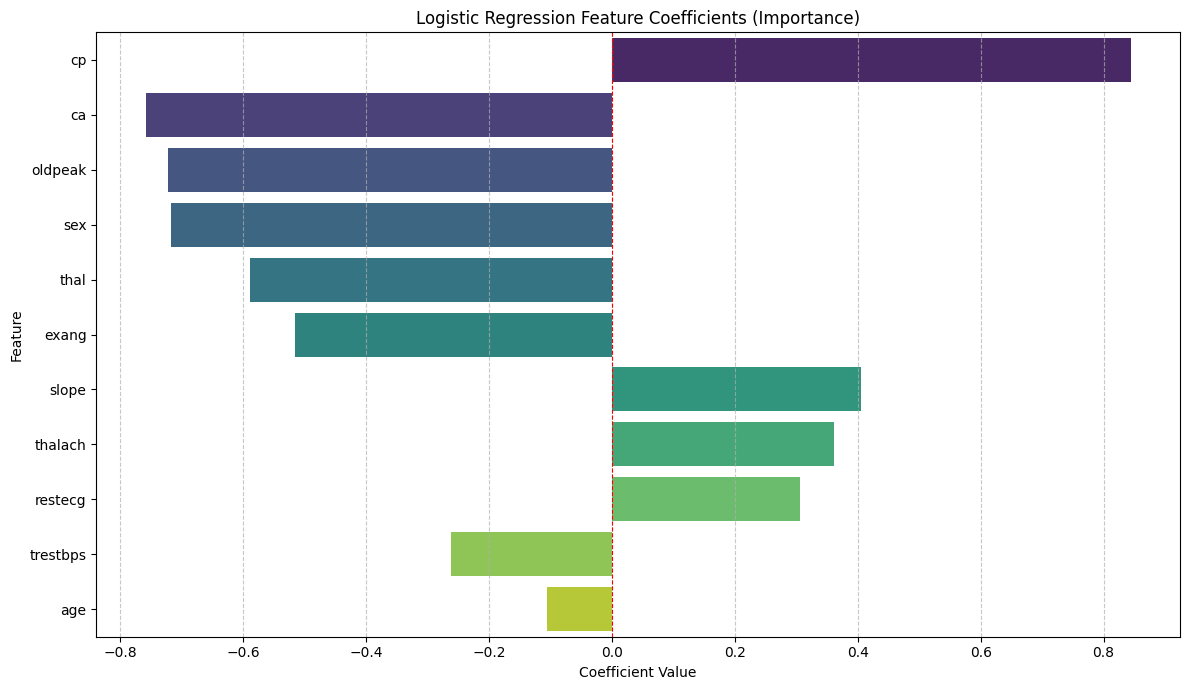

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature names from X (used for training)
feature_names = X.columns

# Get coefficients from the trained model
# For Logistic Regression, coef_ is typically a 2D array if there's more than one class,
# but for binary classification, we can often take the first row.
coefficients = model_filtered.coef_[0]

# Create a DataFrame for easier plotting
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute coefficient value for better visualization
feature_importance_df['Absolute_Coefficient'] = feature_importance_df['Coefficient'].abs()
feature_importance_df = feature_importance_df.sort_values(by='Absolute_Coefficient', ascending=False)

# Create the bar plot
plt.figure(figsize=(12, 7))
sns.barplot(x='Coefficient', y='Feature', hue='Feature', data=feature_importance_df, palette='viridis', legend=False)
plt.title('Logistic Regression Feature Coefficients (Importance)')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.axvline(0, color='red', linestyle='--', linewidth=0.8)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

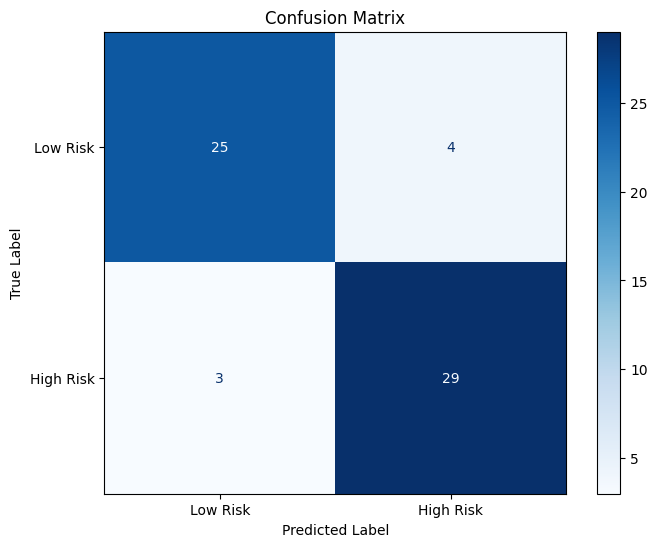

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Define class labels for better readability
class_labels = ['Low Risk', 'High Risk']

# Create the plot using subplots to ensure reliable rendering in Colab
fig, ax = plt.subplots(figsize=(8, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)

# Plot directly onto the created axis
display_cm.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()

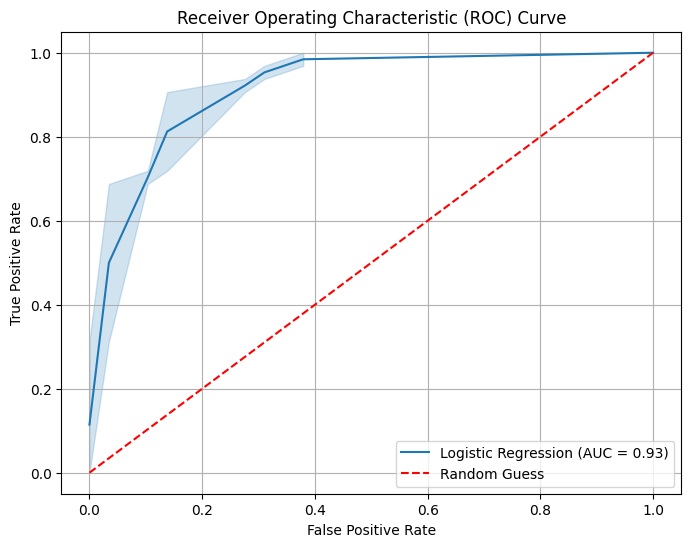

In [31]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# Get predicted probabilities for the positive class (class 1)
y_pred_proba = model_filtered.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Calculate AUC
auc = roc_auc_score(y_test, y_pred_proba)

# Plot ROC curve
plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr, y=tpr, label=f'Logistic Regression (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'r--', label='Random Guess') # Plot random classifier line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()